# BioGuard-X — Notebook 03: Speech Commands Bonus

**Speaker Identity (WHO?) + Spoken Word (WHAT?) + Permission (CAN THEY?)** — three separate checks.

This independent notebook trains an **isolated-word classifier** with hand-crafted audio features and traditional ML only (no Deep Learning). It **does not** retrain your main RAVDESS face/voice/verifier.

**Dataset:** [Google Mini Speech Commands ZIP](https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip) — ~8 words (`no`, `yes`, `down`, `go`, `left`, `up`, `right`, `stop`). Put ZIP (unextracted) in Downloads. `go` → **OPEN**, `stop` → **CLOSE**. Other words are not actions.

**Important:** This does **NOT** recognize exact sentences like “Open the door”. Training on those exact phrases requires examples of those phrases from multiple speakers. Even if a command is correctly recognized, the door must NOT open until speaker identity + permission also pass.

## Setup — new audio-quality fix (v2)

The preceding error was `ValueError: Silent or too-short command audio` in the training cell. The new `speech_commands_research.py` skips and **logs** these bad training samples without letting silence become an allowed command. It retains the strict real-time validation of live commands.

**Both the notebook and the helper must be placed in the same existing project folder.** Restart the kernel after replacing the helper, otherwise Python might keep the old version in memory. No need to redo RAVDESS or Fingerprint.

In [1]:
from pathlib import Path
import time, json, sys
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
import librosa, joblib
from sklearn.metrics import ConfusionMatrixDisplay,confusion_matrix,classification_report
from IPython.display import display
import speech_commands_research as cmd

COMMAND_SOURCE=None  # Searches Downloads/mini_speech_commands.zip automatically
MAX_PER_WORD_TRAIN=180
MAX_PER_WORD_EVAL=45
MODEL=Path('model'); MODEL.mkdir(exist_ok=True)
OUT=Path('outputs')/'speech_commands_bonus';OUT.mkdir(parents=True,exist_ok=True)
print('Python:',sys.executable)
print('Commands dataset:',cmd.find_mini(COMMAND_SOURCE))
print('RAVDESS public_models exists:',(MODEL/'public_models.joblib').exists())
assert getattr(cmd, 'QUALITY_FIX_VERSION', None)=='quality-skip-v2', 'Your speech_commands_research.py is OLD. Replace helper and restart kernel.'
print('Loaded command helper:',cmd.__file__,cmd.QUALITY_FIX_VERSION)

Python: <PROJECT_ROOT>\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Scripts\python.exe
Commands dataset: <PROJECT_ROOT>\Downloads\mini_speech_commands.zip
RAVDESS public_models exists: True
Loaded command helper: <PROJECT_ROOT>\Downloads\BioGuard_Task2_COMPLETE\speech_commands_research.py quality-skip-v2


## 2 — Dataset Exploration and speaker-safe train/validation/test split

Each source file's prefix (before `_nohash_`) denotes the speaker. Splitting randomly by file would let **the same person** appear in train and test; we split by speaker ID first. Labels = 8 isolated English words, not speaker identities.

Mini Speech Commands: split  test  train  val
word                   
down     45    180   45
go       45    180   45
left     45    180   45
no       45    180   45
right    45    180   45
stop     45    180   45
up       45    180   45
yes      45    180   45
Audio validation: 2160 readable WAV files; repaired 0 corrupted cached files; skipped 8000 invalid source files.
First invalid source: __MACOSX/mini_speech_commands/down/._004ae714_nohash_0.wav: invalid WAV in source (first 16 bytes=b'\x00\x05\x16\x07\x00\x02\x00\x00Mac OS X')
Total WAV clips: 2160 speakers: 517


split,test,train,val
word,,,
down,45,180,45
go,45,180,45
left,45,180,45
no,45,180,45
right,45,180,45
stop,45,180,45
up,45,180,45
yes,45,180,45


Speaker overlap between train and val: 0
Speaker overlap between train and test: 0
Speaker overlap between val and test: 0


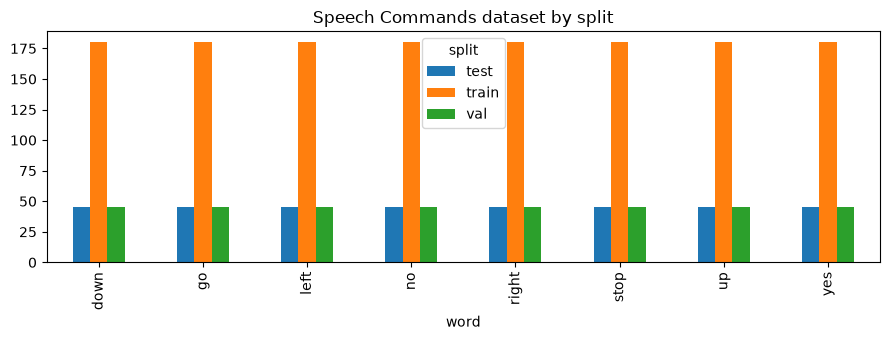

In [2]:
command_manifest=cmd.prepare_mini(COMMAND_SOURCE,max_per_word_train=MAX_PER_WORD_TRAIN,
      max_per_word_eval=MAX_PER_WORD_EVAL)
print('Total WAV clips:',len(command_manifest),'speakers:',command_manifest.speaker.nunique())
display(pd.crosstab(command_manifest.word,command_manifest.split))
for a,b in [('train','val'),('train','test'),('val','test')]:
    x=set(command_manifest[command_manifest.split==a].speaker)
    y=set(command_manifest[command_manifest.split==b].speaker)
    print(f'Speaker overlap between {a} and {b}:',len(x&y))
    assert not(x&y)
fig,ax=plt.subplots(figsize=(9,3.5))
pd.crosstab(command_manifest.word,command_manifest.split).plot.bar(ax=ax)
ax.set_title('Speech Commands dataset by split');plt.tight_layout()
plt.savefig(OUT/'01_dataset_exploration.png',dpi=160);plt.show()

## 3 — Preprocessing and feature extraction: MFCC / Delta / Delta2 / ZCR / RMS

Audio → mono 16kHz → trim silence → normalize duration to 1 sec → frame → FFT → Mel Filter Bank → log → DCT = **MFCC** (13 coefficients). Derivatives of MFCC show motion over time. **ZCR:** fraction of sign changes (zero crossings) per frame. **RMS:** energy/loudness. **82 D = 2×(13+13+13+1+1)** (mean and std for each feature).

Plot sample WAV: command_data\mini_selected\go\train\68487f4c91e1d9f3.wav size: 32044 bytes
WAV header: b'RIFF$}\x00\x00WAVEfmt '


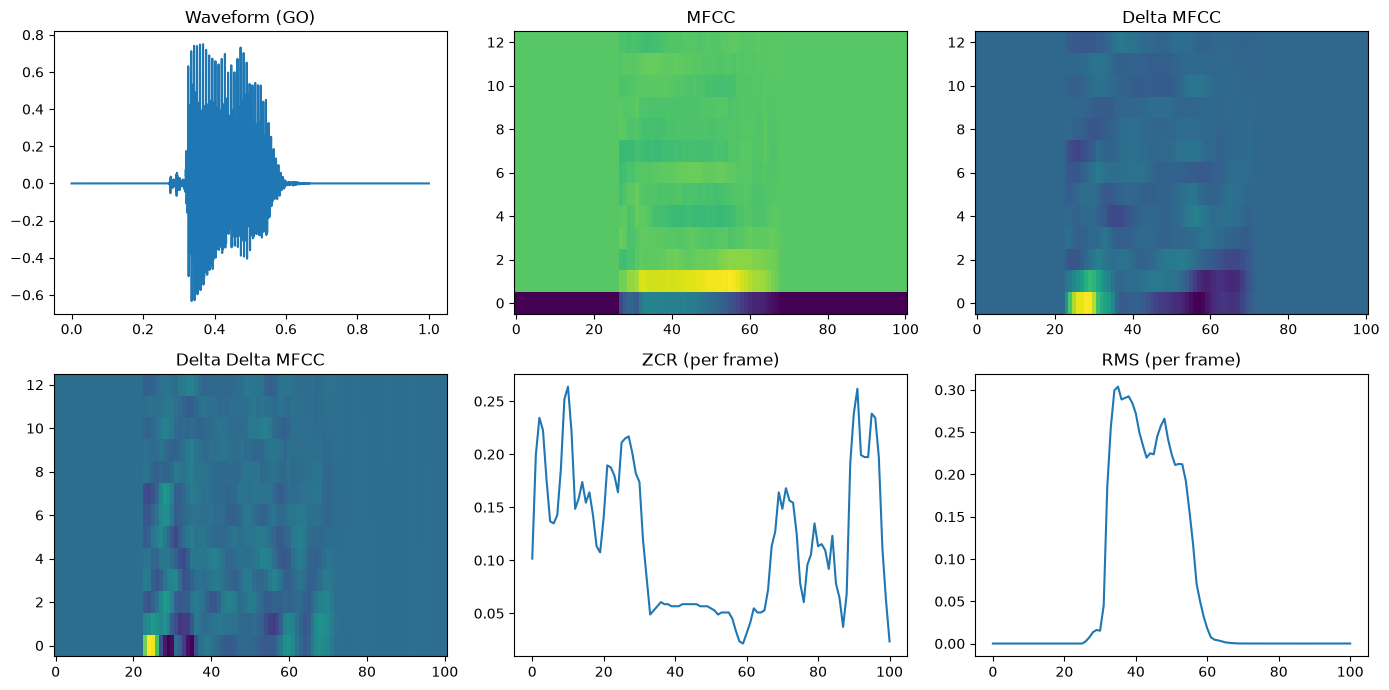

Features: (82,) finite: True


In [3]:
wav=command_manifest.query("word=='go'").iloc[0].path
wav_path=Path(wav)
print('Plot sample WAV:',wav_path,'size:',wav_path.stat().st_size,'bytes')
print('WAV header:',wav_path.read_bytes()[:16])
# In the repaired helper, any bad cached WAV is restored from the original ZIP
# when you re-run the dataset preparation cell above.
y,sr=librosa.load(str(wav_path),sr=16000,mono=True)
mfcc=librosa.feature.mfcc(y=y,sr=sr,n_mfcc=13,n_fft=512,hop_length=160)
d1=librosa.feature.delta(mfcc);d2=librosa.feature.delta(mfcc,order=2)
zcr=librosa.feature.zero_crossing_rate(y,frame_length=512,hop_length=160)[0]
rms=librosa.feature.rms(y=y,frame_length=512,hop_length=160)[0]
fig,axs=plt.subplots(2,3,figsize=(14,7))
axs[0,0].plot(np.arange(len(y))/sr,y);axs[0,0].set_title('Waveform (GO)')
for ax,img,title in zip([axs[0,1],axs[0,2],axs[1,0]],[mfcc,d1,d2],['MFCC','Delta MFCC','Delta Delta MFCC']):
    ax.imshow(img,aspect='auto',origin='lower');ax.set_title(title)
axs[1,1].plot(zcr);axs[1,1].set_title('ZCR (per frame)')
axs[1,2].plot(rms);axs[1,2].set_title('RMS (per frame)')
plt.tight_layout();plt.savefig(OUT/'02_mfcc_zcr_rms.png',dpi=160);plt.show()
vec=cmd.extract_command_features(wav)
assert vec.shape==(82,)
print('Features:',vec.shape,'finite:',np.isfinite(vec).all())

## 4 — Train SVM and Random Forest; select model on validation only

SVM and RF both use **hand-crafted** 82D audio features. No TensorFlow. We choose by validation **macro-F1**, then report held-out test **Accuracy, macro-F1, confusion matrix** for both models. Test speakers were never used to train either model.

In [4]:
t0=time.perf_counter()
command_result=cmd.train_mini(COMMAND_SOURCE,output=str(MODEL/'commands_model.joblib'),
        max_per_word_train=MAX_PER_WORD_TRAIN,max_per_word_eval=MAX_PER_WORD_EVAL)
print('Training seconds:',round(time.perf_counter()-t0,1))
print('Winner selected on validation:',command_result['best'])
display(command_result['comparison'].round(4))
print('Quality report:')
display(command_result['quality_audit'].groupby(['split','status']).size().unstack(fill_value=0))

Mini Speech Commands: split  test  train  val
word                   
down     45    180   45
go       45    180   45
left     45    180   45
no       45    180   45
right    45    180   45
stop     45    180   45
up       45    180   45
yes      45    180   45
Audio validation: 2160 readable WAV files; repaired 0 corrupted cached files; skipped 8000 invalid source files.
First invalid source: __MACOSX/mini_speech_commands/down/._004ae714_nohash_0.wav: invalid WAV in source (first 16 bytes=b'\x00\x05\x16\x07\x00\x02\x00\x00Mac OS X')
Feature audit: 2137 valid, 23 skipped; report: model\commands_quality_audit.csv
Examples of skipped low-quality/broken recordings:
word split                                                       path                                        reason
down train command_data\mini_selected\down\train\893c59bcb28e3c8a.wav ValueError: Silent or too-short command audio
down train command_data\mini_selected\down\train\d207c27263c9240c.wav ValueError: Silent or too-s

<PROJECT_ROOT>\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Selected by validation: SVM command threshold: 0.55
        model  val_accuracy  val_macro_F1  test_accuracy  test_macro_F1
          SVM      0.662953      0.666319       0.669444       0.668748
Random Forest      0.573816      0.575600       0.602778       0.595498
Training seconds: 25.4
Winner selected on validation: SVM


,model,val_accuracy,val_macro_F1,test_accuracy,test_macro_F1
0,SVM,0.6630,0.6663,0.6694,0.6687
1,Random Forest,0.5738,0.5756,0.6028,0.5955


Quality report:


status,skipped,valid
split,,
test,0,360
train,22,1418
val,1,359


### Audio quality audit

After training, inspect `model/commands_quality_audit.csv` and `model/commands_clean_split_counts.csv`. The audit gives **every** clip's valid/skipped status and the error reason. If too few samples remain, the code stops with a clear count rather than inventing results.

In [5]:
quality=pd.read_csv(MODEL/'commands_quality_audit.csv')
print('Skipped samples:',(quality.status=='skipped').sum())
display(quality[quality.status=='skipped'].head(15))
display(pd.read_csv(MODEL/'commands_clean_split_counts.csv'))

Skipped samples: 23


,word,split,speaker,path,status,reason
152,down,train,3bfd30e6,command_data\mini_selected\down\train\893c59bc...,skipped,ValueError: Silent or too-short command audio
161,down,train,3f2b358d,command_data\mini_selected\down\train\d207c272...,skipped,ValueError: Silent or too-short command audio
162,down,train,3f2b358d,command_data\mini_selected\down\train\e1de9756...,skipped,ValueError: Silent or too-short command audio
282,go,train,096456f9,command_data\mini_selected\go\train\f5f66c512d...,skipped,ValueError: Silent or too-short command audio
427,go,train,3f2b358d,command_data\mini_selected\go\train\3d456bdb87...,skipped,ValueError: Silent or too-short command audio
428,go,train,3f2b358d,command_data\mini_selected\go\train\32f7e0240b...,skipped,ValueError: Silent or too-short command audio
430,go,train,3f2b358d,command_data\mini_selected\go\train\b74494fb82...,skipped,ValueError: Silent or too-short command audio
678,left,train,3f2b358d,command_data\mini_selected\left\train\e006111d...,skipped,ValueError: Silent or too-short command audio
818,no,train,096456f9,command_data\mini_selected\no\train\0076d7cc74...,skipped,ValueError: Silent or too-short command audio
819,no,train,096456f9,command_data\mini_selected\no\train\636a3658b2...,skipped,ValueError: Silent or too-short command audio


,word,train,val,test
0,down,177,45,45
1,go,176,45,45
2,left,179,45,45
3,no,177,45,45
4,right,176,44,45
5,stop,179,45,45
6,up,177,45,45
7,yes,177,45,45


## 5 — Compare models + confusion matrices + classification report

Rows = true word, columns = model's predicted word. **Macro-F1** balances the eight labels. Accuracy is overall correct rate. Remember: the command labels are NOT users. A user is verified by RAVDESS's separate speaker verifier and a gallery of newly enrolled employees.

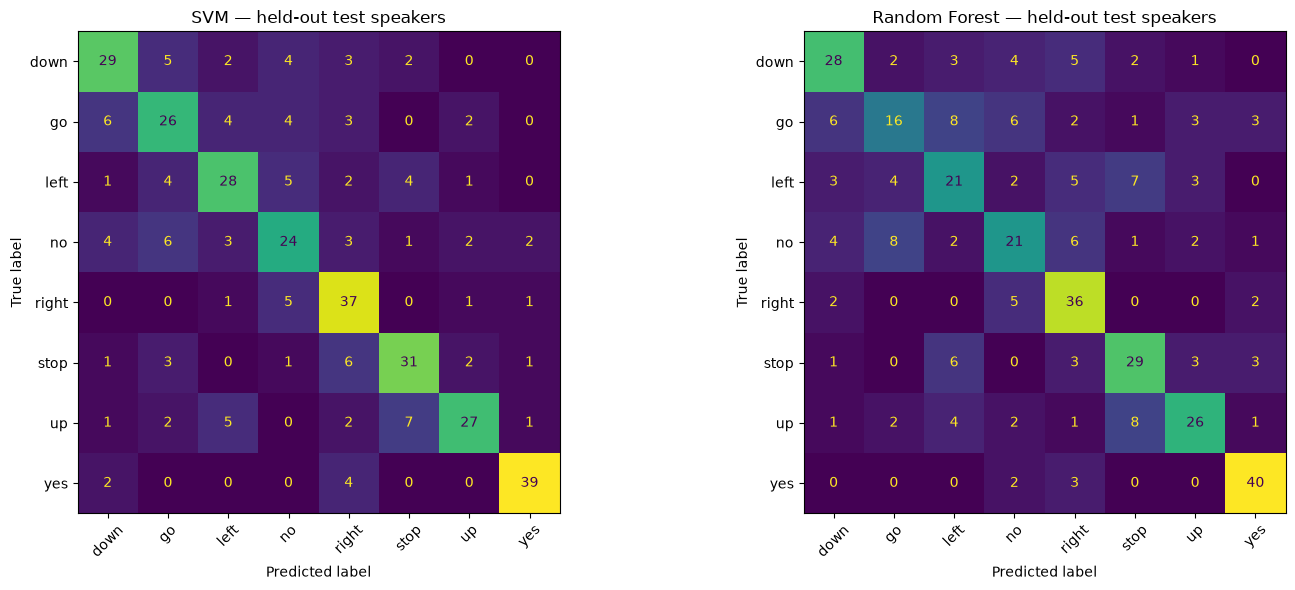

              precision    recall  f1-score   support

        down       0.66      0.64      0.65        45
          go       0.57      0.58      0.57        45
        left       0.65      0.62      0.64        45
          no       0.56      0.53      0.55        45
       right       0.62      0.82      0.70        45
        stop       0.69      0.69      0.69        45
          up       0.77      0.60      0.68        45
         yes       0.89      0.87      0.88        45

    accuracy                           0.67       360
   macro avg       0.67      0.67      0.67       360
weighted avg       0.67      0.67      0.67       360



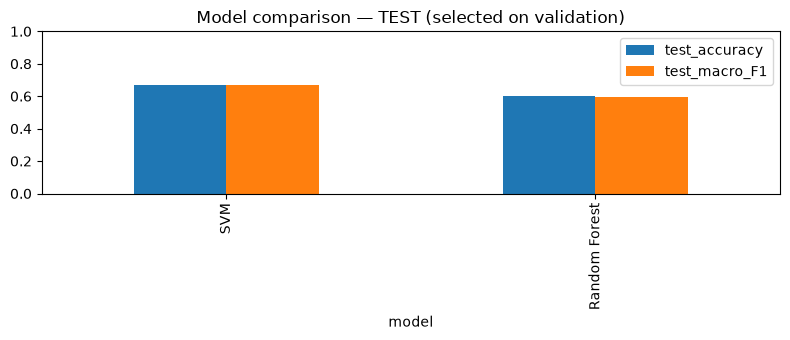

In [6]:
detail=pd.read_csv(MODEL/'commands_test_predictions.csv')
fig,axs=plt.subplots(1,2,figsize=(15,6))
for ax,name in zip(axs,('SVM','Random Forest')):
    rows=detail[detail.model==name]
    cm=confusion_matrix(rows.true,rows.predicted,labels=cmd.WORDS)
    ConfusionMatrixDisplay(cm,display_labels=cmd.WORDS).plot(ax=ax,colorbar=False,xticks_rotation=45)
    ax.set_title(name+' — held-out test speakers')
plt.tight_layout();plt.savefig(OUT/'03_confusion_matrices.png',dpi=160);plt.show()
chosen=detail[detail.model==command_result['best']]
print(classification_report(chosen.true,chosen.predicted,labels=cmd.WORDS,zero_division=0))
fig,ax=plt.subplots(figsize=(8,3.5))
command_result['comparison'].set_index('model')[['test_accuracy','test_macro_F1']].plot.bar(ax=ax)
ax.set_ylim(0,1);ax.set_title('Model comparison — TEST (selected on validation)');plt.tight_layout()
plt.savefig(OUT/'04_model_comparison.png',dpi=160);plt.show()

## 6 — Live-game logic: WHO? + WHAT? + PERMISSION? (Bonus)

For Flask Voice-Only Mode: 

1. `speaker_audio_file`: separate fresh **2–3-second** recording (sufficient duration to compare against the voice template); no camera required.
2. `command_audio_file`: isolated spoken keyword (**GO** or **STOP**) recorded via microphone and passed to command model.
3. `public_models.joblib`: general RAVDESS speaker verification rule; `enrollment_gallery.joblib`: Ziad/Abdo templates added via web app; protected action allowed only if **same speaker verified, known user, and action permission true**.

A single 1-second word is often not enough for robust speaker verification. **Replay attacks are not prevented here**. Demonstrate with consent and state limitations. Never rely on client-side JavaScript to authorize a door.

In [7]:
policy={'abdo':{'open','close'},'ziad':{'open'},'mohamed':set()}
assert cmd.authorized_command('abdo','open',True,policy)
assert not cmd.authorized_command('abdo','open',False,policy)
assert not cmd.authorized_command('ziad','close',True,policy)
assert not cmd.authorized_command('mohamed','open',True,policy)
print('Four permission-gate unit checks passed (not biometric accuracy).')
for word in ['go','stop','yes','no']:
    f=command_manifest[command_manifest.word==word].iloc[0].path
    print('Example:',word,'->',cmd.predict_command(f,path=str(MODEL/'commands_model.joblib')))
print('Flask API: cmd.verify_voice_only_command(command_audio_file,public_package,gallery,command_package,policy,speaker_audio_file=...)')

Four permission-gate unit checks passed (not biometric accuracy).
Example: go -> {'recognized': True, 'word': 'go', 'action': 'open', 'score': 0.9581520788858265}
Example: stop -> {'recognized': True, 'word': 'stop', 'action': 'close', 'score': 0.9257949289772245}
Example: yes -> {'recognized': True, 'word': 'yes', 'action': None, 'score': 0.976047469522459}
Example: no -> {'recognized': True, 'word': 'no', 'action': None, 'score': 0.8368242748036396}
Flask API: cmd.verify_voice_only_command(command_audio_file,public_package,gallery,command_package,policy,speaker_audio_file=...)


## 7 — Model export and integration with Flask

Outputs (shared `model/` dir):
- `commands_model.joblib` — trained classifier, permitted word-to-action mapping and validation confidence threshold
- `commands_comparison.csv` — side-by-side SVM / RF
- `commands_test_predictions.csv` — confusion matrix source for both
- Figures under `outputs/speech_commands_bonus/`

Keep `public_models.joblib` from your separate RAVDESS notebook and `enrollment_gallery.joblib` generated by the Flask Add User flow. **Neither is overwritten** by this notebook. The same `speech_commands_research.extract_command_features()` MUST be called during training and at runtime.

**Exact phrase warning:** The model only knows 8 individual words. You must say **GO** to request Open and **STOP** for Close. To demand “Open the door” exactly, collect and label a different phrase-specific dataset and retrain a phrase model. Unknown commands can still trigger false predictions; test rejection and log errors.
- `commands_quality_audit.csv` — valid and rejected files, with reasons
- `commands_clean_split_counts.csv` — usable records after filtering by class/split


In [8]:
p=MODEL/'commands_model.joblib'
assert p.exists(), 'No exported model. Check previous cells.'
package=joblib.load(p)  # locally generated only
print('Command model:',package['name'],'labels:',package['words'],
      'threshold:',package['confidence_threshold'])
print('Public main model untouched:', (MODEL/'public_models.joblib').exists())
for name in ['commands_model.joblib','commands_comparison.csv','commands_test_predictions.csv']:
    artifact=MODEL/name
    print(name,artifact.exists(),round(artifact.stat().st_size/1024,1) if artifact.exists() else '', 'KB')

Command model: SVM labels: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes'] threshold: 0.55
Public main model untouched: True
commands_model.joblib True 982.6 KB
commands_comparison.csv True 0.2 KB
commands_test_predictions.csv True 13.1 KB


## 8 — Oral exam prep: direct answers

- **MFCC**: cepstral coefficients derived from Mel-scale spectral log energies; they compactly summarize sound timbre.
- **ZCR**: how frequently the waveform changes sign across zero.
- **RMS**: signal root-mean-square amplitude, indicating loudness/energy.
- **Why standardize before SVM?** Different feature magnitudes distort SVM distances.
- **SVM vs RF**: margin-based boundary vs multiple decision trees. Winner must be chosen from VALIDATION, evaluated with held-out TEST.
- **Difference between command and speaker recognition?** Command = **what** is said; speaker = **who** says it.
- **Does a public Speech Commands label prove Abdo said GO?** No — separate gallery verification is mandatory.
- **Why no TensorFlow?** Deep learning is prohibited by assignment. We use traditional feature extraction + scikit-learn.
- **Why challenge+word?** 1s keyword may be weak for voice identity. Even a fresh challenge alone is not reliable anti-spoofing.